# Function 8 — Optimiser

**High-dimensional black box (8-D)**

## What this notebook is for

It reads everything measured for function 8 so far, fits a model to it, and prints
the single input you should submit next. Run it once a week.

## How to use it

1. **Kernel → Restart & Run All.** Every cell runs top to bottom; nothing needs to be
   run out of order.
2. Find the line `>>> NEXT POINT TO SUBMIT` in the RECOMMEND cell's output and copy
   those numbers. **Submit them to function 8 and nothing else** — several functions
   take the same number of inputs, and a point pasted into the wrong one is
   indistinguishable from a valid submission.
3. When the output comes back a week later, scroll to the **ADD A REALISED TRIAL**
   cell, paste the number into `NEW_Y`, and run that cell. It records the result and
   immediately prints the next recommendation.
4. Set `NEW_Y = None` again afterwards, so re-running the notebook cannot log the same
   trial twice.
5. Save the notebook (Ctrl+S) so its output is on disk.

## How this function is being handled right now

The model is **standard GP** and the next point is chosen by **acquisition + trust region**.

The best-modelled function of the eight; the acquisition keeps full control. The search box has been shrunk after growing it produced three declining readings.

The number behind that decision is **Q² = 0.99**. It measures how well the model
predicts a measurement it was *not* shown: remove one observed point, refit on the
rest, predict the one removed, and repeat for all of them. A score of 1 is perfect,
0 means no better than always guessing the average, and below 0 means worse than
that. It is not the same as how well the model fits data it has already seen — that
is near-perfect here and tells you nothing useful. Only the ability to predict
somewhere new justifies spending a week measuring there.

Where the score is high the model is allowed to pick any point it likes. Where it is
low the model is demoted to ranking a short list of small moves away from the best
point already found, so that a wrong answer still lands somewhere sensible.

The **CHECK** cell below recomputes this for three candidate models. Re-run it every
few rounds: the winner shifts as data accumulates. Only switch model on a clear
margin — with a few dozen points, small differences are noise.

*Full background, including what every setting means: `HOW_IT_WORKS.md` in the
project root.*


## 1 · Settings

The only cell you normally edit. `SURROGATE` picks the model, `PROPOSER` picks how
the next point is chosen from it, and the rest tune those two. Plain-language
descriptions of every knob are in `HOW_IT_WORKS.md`.

Each line carries a dated comment explaining why it holds its current value, so the
history of the decisions stays attached to the decisions themselves.


In [1]:
# =====================================================================
# CONFIG  --  edit these as outputs arrive (this is the only cell you tune)
# =====================================================================
# Strategy for this function (High-dimensional black box (8-D)):
# HIGH-DIM: a global GP over 8-D with ~50 points is under-determined, so we go LOCAL. TRUST_REGION=True restricts the search to a box of half-width TR_RADIUS around the current best point (TuRBO idea).
# - Acquisition: **UCB (beta~2)** inside the trust region.
# - ADAPT: if trials keep improving, shrink TR_RADIUS to refine; if they stall, grow it (or move the centre). Check ARD lengthscales - if only a few of the 8 inputs matter, the problem is effectively lower-dim and you can set TRUST_REGION=False.

FUNC_ID     = 8
DIM         = 8

ACQUISITION = "ucb"
BETA        = 0.0   # W8: exploration weight to zero -- maximise the predicted mean. This model has now over-predicted on ALL SEVEN trials (latest -0.104); halving the weight last round did not fix it because the bias is in the model, not the acquisition. With the bias measured, adding any optimism on top is simply adding a known error.
XI          = 0.01

NOISE          = True   # model observation noise (WhiteKernel)

LENGTHSCALE_BOUNDS = (0.01, 10.0)  # (low, high); low bound short => allow sharp peaks

TRUST_REGION = True
TR_RADIUS    = 0.15   # W8: narrowed back. The wider box was a deliberate probe for a better basin; it proposed a point 0.46 away and returned below the incumbent, so the answer is no. Question asked, answered, region restored.

RANDOM_STATE = 0                # change to get a different (still-valid) proposal
TRIAL_BUDGET = 13               # W10: corrected again -- 13 submissions in total, not 14. Display only; nothing in the decision logic reads it.
EPS = 1e-6                      # keep every proposed coordinate strictly inside
                                # (0,1): search + clip to [EPS, 1-EPS], so points
                                # always read 0.000001 .. 0.999999 (never 0 or 1)

# ---------------------------------------------------------------------
# WEEK 4 -- surrogate and proposer are now explicit choices
# W4: Q2 = 0.99, the best-modelled function; acquisition keeps control. Radius shrunk 0.30 -> 0.15 and beta 2.0 -> 1.5, reversing the W3 growth that produced three declining readings.
# ---------------------------------------------------------------------
SURROGATE  = "matern"     # "matern" | "additive" | "quadratic"  (run the CHECK cell)
TRANSFORM  = None          # None | "log" | "log10abs"  -- what the model is fitted to
PROPOSER   = "acquisition"     # "acquisition" | "local" | "replicate"

SCORE           = "ei"   # how local candidates are ranked: "ei" | "ucb" | "mean"
STEP_FRAC       = 0.33   # local step = this fraction of the dimension's lengthscale
INERT_THRESHOLD = 5.0    # lengthscale above this => treated as inert, never stepped
                         # (stepping an inert axis measures nothing AND saturates
                         #  the step, which is what pinned a coordinate to the
                         #  boundary in week 3)
PLAUSIBLE_MAX   = None   # hard ceiling on a believable prediction; drops candidates
                         # above it. Needed for the quadratic surrogate, which can
                         # interpolate perfectly and still extrapolate absurdly.
REPLICATE_SHIFT = 0.05   # how far the "replicate" proposer moves the inert axes
MIN_STEP        = 0.02   # W8: floor on the local step size (see bbo_toolkit.local_candidates).


## 2 · Load the data

Imports the shared engine from `bbo_toolkit.py` in the project root, then loads this
function's starting data (`initial_inputs.npy`, `initial_outputs.npy`, never
modified) together with every trial submitted since (`new_trials.csv`, appended to
each week). Nothing here needs editing.


In [2]:
# =====================================================================
# Setup: import the shared toolkit and locate this function's data
# =====================================================================
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")   # silence GP convergence chatter

# This notebook lives in .../function_<id>/ ; the toolkit sits in the project root.
HERE = Path.cwd()
for p in (HERE, HERE.parent):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from bbo_toolkit import (
    fit_gp, fit_surrogate, expected_improvement, upper_confidence_bound,
    propose_next_point, propose_local, trust_region_bounds, loo_q2,
)

# Data files: initial_*.npy are IMMUTABLE; new realised trials accumulate in a CSV
# so your work persists across sessions (append-only log).
INIT_X = HERE / "initial_inputs.npy"
INIT_Y = HERE / "initial_outputs.npy"
LOG_CSV = HERE / "new_trials.csv"    # created on first add
assert INIT_X.exists(), f"initial_inputs.npy not found next to this notebook ({HERE})"

def load_all():
    """Return the full observed dataset = initial points + every appended trial."""
    X = np.atleast_2d(np.load(INIT_X).astype(float))
    y = np.load(INIT_Y).astype(float).ravel()
    if LOG_CSV.exists():
        df = pd.read_csv(LOG_CSV)
        if len(df):
            Xnew = df[[f"x{j}" for j in range(DIM)]].to_numpy(float)
            ynew = df["y"].to_numpy(float)
            X = np.vstack([X, Xnew]); y = np.concatenate([y, ynew])
    return X, y

def n_new_trials():
    if LOG_CSV.exists():
        return len(pd.read_csv(LOG_CSV))
    return 0

## 3 · Recommend the next point

Fits the model to everything measured so far and prints the point to submit.

Read the output in this order. The header tells you how much data and how much of
the ten-trial budget you have left. The `rule` line says which model and which
selection method produced the point. Then the point itself, with the model's
prediction and its uncertainty.

The last line matters most. A point predicted **above** the current best is an
attempt at a new record. One predicted **below** is a deliberate purchase of
information — refining the shape of a peak, or measuring how noisy the function is —
which is a legitimate use of a trial as long as you know that is what you are doing.
The distance to the incumbent tells you how adventurous the proposal is.

When the local proposer is in use it also prints the candidates it considered and
rejected, so the choice can be audited rather than taken on faith.


=== FUNCTION 8 ===
observed points: 51  (initial 40 + new 11);  new-trial budget: 11/13
surrogate: matern   target: y   proposer: acquisition
best so far: y=9.973 at x=[0.109875, 0.159028, 0.146049, 0.000001, 0.870966, 0.476197, 0.211811, 0.589001]
rule: UCB (beta=0.0)  [trust region r=0.15]
--------------------------------------------------------------
>>> NEXT POINT TO SUBMIT:
    [0.108546, 0.163472, 0.141025, 0.000001, 0.863819, 0.487005, 0.208507, 0.599440]
    predicted y: 9.973 +/- 0.001815
    below the incumbent   |   distance to it: 0.018
    lengthscales (small = influential): [4.036, 5.811, 3.189, 7.57, 9.297, 5.825, 4.047, 10.0]


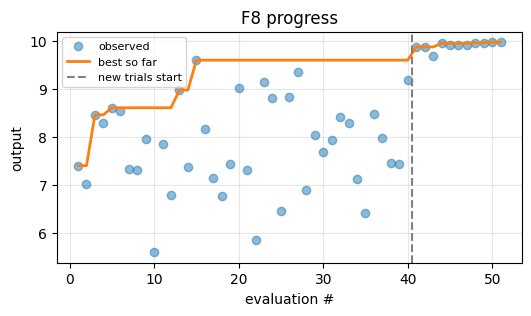

In [3]:
# =====================================================================
# RECOMMEND: fit the chosen surrogate on all data so far and print the next
# point to run. Re-run this cell any time; it always reflects the latest trials.
#
# Two things changed in week 4:
#   * SURROGATE selects the model. The Matern GP allows any interaction between
#     inputs, which is expensive when data is scarce; "additive" forbids
#     interactions and "quadratic" fits a polynomial trend with a GP on the
#     residual. Which one is right is an empirical question -- run the CHECK cell.
#   * PROPOSER selects HOW the point is chosen. "acquisition" is the classic
#     EI/UCB optimisation over the whole (or trust-region) box, and is justified
#     only when the surrogate can predict points it has not seen. "local" instead
#     scores a handful of small moves away from the current best, so the model
#     only has to RANK nearby options rather than locate a global optimum.
# =====================================================================
def _lengthscales(model):
    try:
        for p, v in model.kernel_.get_params().items():
            if p.endswith("length_scale") and not p.endswith("bounds"):
                v = np.atleast_1d(v).astype(float)
                if np.all(v < 1e4):
                    return v
    except Exception:
        pass
    return None


def _transform(y):
    if TRANSFORM == "log":
        return np.log(y), "log y"
    if TRANSFORM == "log10abs":
        return np.log10(np.abs(y)), "log10|y|"
    return y, "y"


def recommend(verbose=True, plot=True):
    X, y = load_all()
    y_fit, ylabel = _transform(y)

    model = fit_surrogate(
        X, y_fit, kind=SURROGATE, noise=NOISE,
        length_scale_bounds=LENGTHSCALE_BOUNDS, random_state=RANDOM_STATE,
    )
    # Step sizes come from a plain Matern fit even when another surrogate ranks
    # the candidates: a trend model's residual lengthscales describe what the
    # trend left over, not the scale on which the function actually varies.
    ref = model if SURROGATE == "matern" else fit_surrogate(
        X, y_fit, kind="matern", noise=NOISE,
        length_scale_bounds=LENGTHSCALE_BOUNDS, random_state=RANDOM_STATE,
    )
    ls = _lengthscales(ref)

    best_i = int(np.argmax(y_fit))
    best_x = X[best_i]
    y_best_fit = float(np.max(np.ravel(model.predict(X))))

    table = None
    if PROPOSER == "local":
        x_next, table = propose_local(
            model, X, y_fit, lengthscales=ls, step_frac=STEP_FRAC,
            score=SCORE, xi=XI, beta=BETA, plausible_max=PLAUSIBLE_MAX,
            inert_threshold=INERT_THRESHOLD, min_step=MIN_STEP,
            eps=EPS, verbose=verbose,
        )
        how = f"local candidates ranked by {SCORE.upper()}"

    elif PROPOSER == "replicate":
        x_next = best_x.copy()
        for j in range(DIM):
            if ls is None or ls[j] > INERT_THRESHOLD:
                shift = -REPLICATE_SHIFT if x_next[j] > 0.5 else REPLICATE_SHIFT
                x_next[j] = float(np.clip(x_next[j] + shift, EPS, 1.0 - EPS))
        how = "near-replicate of the incumbent (inert axes only) to measure noise"

    else:
        bounds = (trust_region_bounds(best_x, TR_RADIUS, EPS, 1.0 - EPS)
                  if TRUST_REGION else (EPS, 1.0 - EPS))
        x_next, _ = propose_next_point(
            model, dim=DIM, acquisition=ACQUISITION, xi=XI, beta=BETA,
            y_best=y_best_fit, bounds=bounds, random_state=RANDOM_STATE,
        )
        how = (f"{ACQUISITION.upper()} "
               f"({'beta='+str(BETA) if ACQUISITION=='ucb' else 'xi='+str(XI)})"
               + (f"  [trust region r={TR_RADIUS}]" if TRUST_REGION else ""))

    x_next = np.clip(np.asarray(x_next, dtype=float).ravel(), EPS, 1.0 - EPS)

    mu, sd = model.predict(x_next.reshape(1, -1), return_std=True)
    mu, sd = float(np.ravel(mu)[0]), float(np.ravel(sd)[0])

    if verbose:
        print(f"=== FUNCTION {FUNC_ID} ===")
        print(f"observed points: {len(y)}  (initial {len(y)-n_new_trials()} + "
              f"new {n_new_trials()});  new-trial budget: {n_new_trials()}/{TRIAL_BUDGET}")
        print(f"surrogate: {SURROGATE}   target: {ylabel}   proposer: {PROPOSER}")
        print(f"best so far: y={y[int(np.argmax(y))]:.4g} at x=["
              + ", ".join(f"{v:.6f}" for v in X[int(np.argmax(y))]) + "]")
        print(f"rule: {how}")
        print("-" * 62)
        print(">>> NEXT POINT TO SUBMIT:")
        print("    [" + ", ".join(f"{v:.6f}" for v in x_next) + "]")
        if TRANSFORM == "log":
            print(f"    predicted: exp(mu)={np.exp(mu):.4g}  "
                  f"(log-space {mu:.3f} +/- {sd:.3f})")
        else:
            print(f"    predicted {ylabel}: {mu:.4g} +/- {sd:.4g}")
        print(f"    {'ABOVE' if mu > y_fit[best_i] else 'below'} the incumbent"
              f"   |   distance to it: {np.linalg.norm(x_next - best_x):.3f}")
        if ls is not None:
            print("    lengthscales (small = influential):",
                  np.round(ls, 3).tolist())

    if plot:
        _progress_plot(X, y)
    return x_next, model


def _progress_plot(X, y):
    n_init = len(y) - n_new_trials()
    running_best = np.maximum.accumulate(y)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(range(1, len(y)+1), y, "o", alpha=0.5, label="observed")
    ax.plot(range(1, len(y)+1), running_best, "-", lw=2, label="best so far")
    ax.axvline(n_init + 0.5, ls="--", c="gray", label="new trials start")
    ax.set_xlabel("evaluation #"); ax.set_ylabel("output"); ax.legend(fontsize=8)
    ax.set_title(f"F{FUNC_ID} progress"); ax.grid(alpha=0.3); plt.show()

x_next, model = recommend()


## 4 · Check: is this still the right model? *(optional, slow)*

Recomputes the leave-one-out score for three candidate models on this function's
current data, and marks which one is in use.

This takes a minute or two because it refits the model once per observation. You do
not need to run it every week — every few rounds is enough. If a different model
wins by a clear margin (roughly 0.1 or more), change `SURROGATE` in the settings
cell and note the change in `WEEKLY_LOG.md`.


In [4]:
# =====================================================================
# CHECK (optional, slow): which surrogate actually predicts this function best?
# =====================================================================
# Leave-one-out Q2: remove each observation, refit on the rest, predict the one
# removed. Q2 = 1 is perfect; Q2 = 0 is no better than always guessing the mean;
# Q2 < 0 is worse than that. This is the test of whether the surrogate has earned
# the right to pick a point somewhere nobody has measured -- in-sample fit does
# NOT answer that (every model here interpolates its own data almost perfectly).
#
# Re-run this every few rounds. The winner changes as data accumulates, and a
# challenger should only replace the incumbent on a clear margin (>= 0.1);
# with a few dozen points, smaller differences are noise.
X, y = load_all()
y_fit, _ = _transform(y)
for kind in ("matern", "additive", "quadratic"):
    try:
        q2 = loo_q2(X, y_fit, kind=kind, n_restarts_optimizer=2,
                    random_state=RANDOM_STATE)
        flag = "   <-- in use" if kind == SURROGATE else ""
        print(f"  {kind:<10}  LOO Q2 = {q2:+.3f}{flag}")
    except Exception as exc:
        print(f"  {kind:<10}  failed: {exc}")


  matern      LOO Q2 = +0.995   <-- in use


  additive    LOO Q2 = +1.000


  quadratic   LOO Q2 = +0.999


## 5 · Record the result, get the next point

After the output arrives, paste it into `NEW_Y` and run this cell. It appends the
point and its result to `new_trials.csv` — which is what makes the history survive
between sessions — then refits and prints the next recommendation straight away.

`NEW_X` defaults to the point this notebook last recommended. If you submitted
something different, edit it to match what you actually ran; the log has to record
reality, not intention.

Afterwards set `NEW_Y = None` again. Left filled in, the next run of this notebook
would append the same trial a second time and quietly corrupt the record.


In [5]:
# =====================================================================
# ADD A REALISED TRIAL: after you run the recommended point in the real
# experiment and get its output, record it here, then re-run to get the
# NEXT recommendation. (Appends to new_trials.csv, so it persists.)
# =====================================================================
# 1) paste the point you actually submitted (length must be DIM, values in [0,1])
NEW_X = list(x_next)          # defaults to the last recommendation; edit if you ran a different point
# 2) paste the output you observed for it
NEW_Y = None

def append_trial(new_x, new_y):
    new_x = np.asarray(new_x, dtype=float).ravel()
    assert new_x.shape[0] == DIM, f"NEW_X must have length {DIM}"
    assert (new_x >= -1e-9).all() and (new_x <= 1+1e-9).all(), "inputs must be in [0,1]"
    assert new_y is not None, "Set NEW_Y to the observed output before running."
    row = {f"x{j}": float(new_x[j]) for j in range(DIM)}
    row["y"] = float(new_y)
    df = pd.read_csv(LOG_CSV) if LOG_CSV.exists() else pd.DataFrame(columns=list(row))
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(LOG_CSV, index=False)
    print(f"Recorded trial #{len(df)}: x={np.round(new_x,4).tolist()} -> y={new_y}")
    print(f"Saved to {LOG_CSV.name}. Re-run the RECOMMEND cell for the next point.")

if NEW_Y is not None:
    append_trial(NEW_X, NEW_Y)
    x_next, gp = recommend()          # immediately show the next recommendation
else:
    print("Set NEW_Y to the observed output (and adjust NEW_X if needed), then run this cell.")

Set NEW_Y to the observed output (and adjust NEW_X if needed), then run this cell.
